In [1]:
!pip install -q "transformers==4.46.3" "accelerate==1.0.1" "peft==0.13.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 66.9 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 70.4 MB/s eta 0:00:00:00:01


In [2]:
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments,EarlyStoppingCallback
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import wandb
from datasets import load_dataset,  Dataset
import random
import matplotlib.pyplot as plt

2026-05-07 09:11:12.502026: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778145072.993934      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778145073.104432      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778145074.189100      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778145074.189141      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778145074.189144      57 computation_placer.cc:177] computation placer alr

In [ ]:
import os
# T4 x2: để trống CUDA_VISIBLE_DEVICES để dùng cả 2 GPU qua DataParallel
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# LƯU Ý: KHÔNG set CUDA_LAUNCH_BLOCKING=1 — chỉ bật khi cần debug CUDA error,
# vì nó làm training chậm 5-10 lần.
# Nếu gặp CUDA assert (do custom modeling.py + DataParallel không tương thích),
# bỏ comment dòng dưới để force chạy single T4:
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [4]:
# Kiểm tra GPU
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
#dataset = load_dataset("NghiemAbe/Legal-training-datasets")
dataset = load_dataset("anti-ai/ViNLI-Zalo-supervised")

README.md:   0%|          | 0.00/133 [00:00<?, ?B/s]

law_vi.jsonl.gz:   0%|          | 0.00/37.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/32980 [00:00<?, ? examples/s]

In [6]:
# print(dataset["train"][0:5])

In [7]:
def restructure_data(split):
    query_list = dataset[split]['query']
    positives = dataset[split]['positive']
    #negatives = dataset[split]['negative']
    negatives = dataset[split]['hard_neg']
    
    samples = []
    for q, pos, neg in zip(query_list, positives, negatives):
        samples.append({"query": q, "document": pos, "label": 1})
        samples.append({"query": q, "document": neg, "label": 0})
    random.shuffle(samples)  # optional but recommended
    return Dataset.from_list(samples)

In [8]:
full_train_dataset = restructure_data("train")

In [9]:
# print(train_dataset[0:5])

In [10]:
split_dataset = full_train_dataset.train_test_split(test_size=0.1, seed=42)
temp_train = split_dataset["train"]
test_dataset = split_dataset["test"]

train_valid_split = temp_train.train_test_split(test_size=0.1, seed=42)
train_dataset = train_valid_split["train"]
valid_dataset = train_valid_split["test"]

In [11]:
# Kiểm tra lại
print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(valid_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 53427
Validation samples: 5937
Test samples: 6596


In [12]:
tokenizer = AutoTokenizer.from_pretrained("Alibaba-NLP/gte-multilingual-reranker-base", trust_remote_code=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

In [13]:
def tokenize_function(examples):
    tokenized = tokenizer(
        examples["query"],
        examples["document"],
        truncation=True,
        padding="max_length",
        max_length=512
    )
    tokenized["labels"] = [float(label) for label in examples["label"]]
    return tokenized

In [14]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=train_dataset.column_names
)
tokenized_valid = valid_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=valid_dataset.column_names
)
tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=test_dataset.column_names
)


Map:   0%|          | 0/53427 [00:00<?, ? examples/s]

Map:   0%|          | 0/5937 [00:00<?, ? examples/s]

Map:   0%|          | 0/6596 [00:00<?, ? examples/s]

In [15]:
# Kiểm tra lại
print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(valid_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 53427
Validation samples: 5937
Test samples: 6596


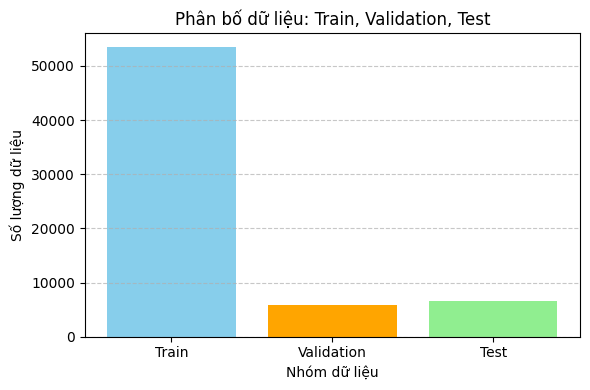

In [16]:
data_counts = {
    'Train': len(train_dataset),
    'Validation': len(valid_dataset),
    'Test': len(test_dataset)
}

# Vẽ biểu đồ cột
plt.figure(figsize=(6, 4))
plt.bar(data_counts.keys(), data_counts.values(), color=['skyblue', 'orange', 'lightgreen'])
plt.title('Phân bố dữ liệu: Train, Validation, Test')
plt.ylabel('Số lượng dữ liệu')
plt.xlabel('Nhóm dữ liệu')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [17]:
model = AutoModelForSequenceClassification.from_pretrained("Alibaba-NLP/gte-multilingual-reranker-base", trust_remote_code=True)

config.json: 0.00B [00:00, ?B/s]

configuration.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/Alibaba-NLP/new-impl:
- configuration.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/Alibaba-NLP/new-impl:
- modeling.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/612M [00:00<?, ?B/s]

In [18]:
def compute_metrics(pred):
    labels = pred.label_ids
    scores = pred.predictions.squeeze()  # shape (batch_size,)
    preds = (scores > 0).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="binary"),
        "recall": recall_score(labels, preds, average="binary"),
        "f1": f1_score(labels, preds, average="binary"),
    }

In [ ]:
import wandb
from transformers import TrainingArguments, EarlyStoppingCallback, TrainerCallback

wandb.login(key='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')

early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,
    early_stopping_threshold=0.01
)


# Callback in tiến độ ra stdout. Kaggle không render tqdm HTML widget,
# nên cần print plain-text để thấy progress live.
class ConsoleProgressCallback(TrainerCallback):
    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step > 0 and state.global_step % 10 == 0:
            total = state.max_steps or 1
            pct = 100 * state.global_step / total
            print(f"  ▶ step {state.global_step}/{total} ({pct:.1f}%) | epoch {state.epoch:.2f}", flush=True)

    def on_log(self, args, state, control, logs=None, **kwargs):
        if not logs:
            return
        parts = [f"step={state.global_step}"]
        for k, v in logs.items():
            parts.append(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}")
        print("  📊 " + " | ".join(parts), flush=True)

    def on_epoch_end(self, args, state, control, **kwargs):
        print(f"  ✓ Epoch {state.epoch:.0f} xong (step {state.global_step})", flush=True)


console_cb = ConsoleProgressCallback()


# ==== CẤU HÌNH CHO KAGGLE GPU T4 x2 (2 × 16GB) ====
# Trainer sẽ tự dùng cả 2 GPU qua DataParallel khi thấy CUDA_VISIBLE_DEVICES
# không giới hạn. Mỗi T4 xử lý batch = per_device_train_batch_size độc lập.
# Effective batch = per_device × grad_accum × num_gpus = 4 × 8 × 2 = 64.
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",             # ← đổi từ "epoch" để thấy log sớm
    logging_steps=10,                     # ← log mỗi 10 step
    learning_rate=2e-5,
    per_device_train_batch_size=4,        # ← mỗi T4 16GB vừa với model ~600MB + seq 512
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,        # ← effective batch = 4 × 8 × 2 GPU = 64
    num_train_epochs=10,
    disable_tqdm=True,                    # ← tắt tqdm HTML (Kaggle không render)
    weight_decay=0.25,
    save_total_limit=3,
    optim="adamw_torch",
    fp16=True,                            # ← T4 có Tensor Cores, fp16 chạy tốt
    max_grad_norm=0.6,
    warmup_ratio=0.2,
    group_by_length=False,                # ← TẮT: tránh pre-scan 53k samples
    report_to="wandb",
    load_best_model_at_end=True,
    label_names=['labels'],
    lr_scheduler_type="linear",
    remove_unused_columns=False,
    dataloader_num_workers=2,             # ← load data song song cho 2 GPU
    dataloader_pin_memory=True,
)

In [20]:
print(tokenized_train[0].keys())


dict_keys(['input_ids', 'attention_mask', 'labels'])


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback, console_cb],   # ← thêm console_cb
)

In [ ]:
# Huấn luyện model
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


In [ ]:
# Lưu mô hình
model.save_pretrained("rerank_model")
tokenizer.save_pretrained("rerank_model")

## Auto push rerank model lên Hugging Face Hub


In [ ]:
HF_REPO_ID = "bhuy71/rerank_model"  
PRIVATE    = False              


import os
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, create_repo

# Load token từ Kaggle Secrets (tên secret phải là HF_TOKEN)
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
login(token=os.environ["HF_TOKEN"])

# Tạo repo nếu chưa có
create_repo(HF_REPO_ID, private=PRIVATE, exist_ok=True, token=os.environ["HF_TOKEN"])

# Push cross-encoder model + tokenizer. Dùng `trainer.model` để lấy best model
trainer.model.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"])
tokenizer.push_to_hub(HF_REPO_ID, token=os.environ["HF_TOKEN"])
print(f"✓ Rerank model + tokenizer pushed to https://huggingface.co/{HF_REPO_ID}")